<a href="https://colab.research.google.com/github/SyuzannaKhalatyaning/CS156-Assignment/blob/main/CS156_First_pipeline_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What is Syuzi doing? Classifying my photo archive by activity

CS156 Pipeline Assignment 1

## 1. The idea
As a Minerva student my life splits into studying, working, socializing and exploring whichever rotation city I am in, and sometimes I can't tell which of these I am doing. My phone holds 12,365 images, and I wanted to know what actually fills my gallery. In this project I build a pipeline that classifies a photo into one of three activities: work/study, socials, or exploration. I also wanted to learn how image classification works, since I had not worked with images before.

I trained image classifiers to sort my photos into three classes:

| class | how I labeled it |
|---|---|
| `work_study` | my laptop screen is visible and shows a tab that proves I was working or studying (not a movie) |
| `social` | 3+ people, or a table with more food than one person could eat, or a crowd/event |
| `exploration` | scenery fills at least ~60% of the frame |

`social` and `exploration` overlap by design (some scenery photos have friends in them). I wanted to see whether a model could separate them even though I sometimes can't.

I compare four conditions: a **majority-class baseline**, **logistic regression on color features**, **logistic regression on frozen MobileNetV2 features**, and a **small CNN trained from scratch**.

I expected overlap between socials and exploration (some exploration photos include friends) and wanted to see whether the model could separate them, even though I struggled to do it myself.

**A limitation I created**. To enlarge the work/study class, I deliberately took about 60 extra work/study photos on a single day. They are very similar (same desk, same laptop), so they are not independent samples.

Privacy. The photos stay in my private Google Drive. The repository contains only code, figures and text.

## 2. Pipeline diagram
The full diagram is in the GitHub README (`pipeline_diagram.png`).

> **To fix in the diagram:** it still says photos are grouped into **2-hour** sessions. The final code uses **15-minute** sessions (see Section 4). It also mentions "grouped 5-fold CV"; that is added in Section 9b below.

In words: raw photos → manual labeling into 3 Drive folders → read capture date → group into sessions → grouped, class-stratified train/val/test split → resize to 224×224 and cache → four models → predictions on test → errors, metrics and plots.

## 3. Data: ingestion and preprocessing

**Ingestion.** I sorted photos into three folders on Google Drive (`Work`, `Socials`, `Exploration`). A separate "nature" folder was merged into `exploration`. Photos can be `.jpg`, `.png` or `.heic` (iPhone format), so I use `pillow-heif` to open HEIC files.

**Preprocessing.**
1. Read each photo's capture date from its EXIF metadata (fallback: the date in the filename).
2. Fix phone rotation (`exif_transpose`), convert to RGB, resize to 224×224 and cache locally so training doesn't re-read Drive every epoch.
3. Scale pixels to [0, 1] by dividing by 255 (inside the CNN's first layer).
4. Augmentation (random flip, small rotation, zoom) is applied **to training data only**, and only for the CNN.

In [1]:
#Setup: mount Drive and install the HEIC reader (run once per session)
from google.colab import drive
drive.mount('/content/drive')
!pip install -q pillow-heif

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 41.2 MB/s eta 0:00:00


In [2]:
# Find all photos and count them per class
from pathlib import Path
import pandas as pd

DATA_DIR = Path('/content/drive/MyDrive/data')

# folder name on Drive -> short label used everywhere else
FOLDERS = {'Work': 'work_study', 'Socials': 'social', 'Exploration': 'exploration'}
EXTS = {'.jpg', '.jpeg', '.png', '.heic'}

rows = []
for folder, label in FOLDERS.items():
    for p in (DATA_DIR / folder).rglob('*'):          # rglob also finds photos in subfolders
        if p.suffix.lower() in EXTS:
            rows.append({'path': str(p), 'label': label})

df = pd.DataFrame(rows)
print(df['label'].value_counts())

label
exploration    230
work_study     188
social          71
Name: count, dtype: int64


In [3]:
# Read each photo's capture date (EXIF first, then the filename)
import re
from PIL import Image
import pillow_heif
pillow_heif.register_heif_opener()

def get_date(path):
    # 1) EXIF "date taken" (tag 36867) or "date modified" (tag 306)
    try:
        exif = Image.open(path).getexif()
        d = exif.get_ifd(0x8769).get(36867) or exif.get(306)
        if d:
            return pd.to_datetime(d, format='%Y:%m:%d %H:%M:%S')
    except Exception:
        pass
    # 2) fall back to a date in the filename, e.g. 20260911_152838
    m = re.search(r'(20\d{6})[_-]?(\d{6})?', Path(path).name)
    if m:
        try:
            return pd.to_datetime(m.group(1), format='%Y%m%d')
        except Exception:
            pass
    return pd.NaT

df['date'] = df['path'].apply(get_date)
print(df['date'].isna().sum(), 'photos have no date')
print(df['date'].min(), '->', df['date'].max())
df = df.sort_values('date').reset_index(drop=True)
df.to_csv(DATA_DIR / 'labels_v1.csv', index=False)   # saved so I don't have to redo this

0 photos have no date
2024-08-07 13:25:33 -> 2026-10-12 21:51:16


## 4. Splitting the data

**Why not a random split?** Photos from one event look almost identical. If some land in train and some in test, the model is graded on near-copies of what it studied. So I group photos into **sessions** (a new session starts after a gap in time) and keep each session entirely in one split. `StratifiedGroupKFold` does this while keeping class proportions balanced.

**How the split evolved** (this is what the results below are built on):

| attempt | what happened |
|---|---|
| 1. Split by date (oldest 70% train, newest 15% test) | `work_study` was missing from the test set. Accuracy of 90.5% was meaningless and `classification_report` crashed with a class-count `ValueError`. |
| 2. Grouped, stratified split with **2-hour** sessions | `work_study` photos were not spread across splits; the CNN still got 0 work/study photos right on the confusion matrix. |
| 3. Same split with **15-minute** sessions (final) | Gave the split below. |

**A known weakness of the final split:** about 60 of my work/study photos were taken on one day (I took extra to balance the classes). Because they are close in time, many form a few huge sessions, so the split put **150 of the 174 validation photos in `work_study`** but only **32 in train**. Section 7 shows what this did to the CNN.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold

# 1) sessions: a new session starts when the gap to the previous photo exceeds 15 minutes
df = df.sort_values('date').reset_index(drop=True)
df['session'] = (df['date'].diff() > pd.Timedelta(minutes=15)).cumsum()
print('Number of sessions:', df['session'].nunique())

groups, y = df['session'], df['label']

# 2) test set: 1 of 7 folds, about 14% of the photos
outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
trainval_idx, test_idx = next(outer.split(df, y, groups))

# 3) validation set: 1 of 6 folds of what remains, about 14% of the total
trainval = df.iloc[trainval_idx]
inner = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(inner.split(trainval, trainval['label'], trainval['session']))

train, val, test = trainval.iloc[tr_idx], trainval.iloc[va_idx], df.iloc[test_idx]

# 4) check class counts in each split
for name, part in [('train', train), ('val', val), ('test', test)]:
    print(name, len(part)); print(part['label'].value_counts(), '\n')

Number of sessions: 131
train 265
label
exploration    169
social          64
work_study      32
Name: count, dtype: int64 

val 174
label
work_study     150
exploration     23
social           1
Name: count, dtype: int64 

test 50
label
exploration    38
work_study      6
social          6
Name: count, dtype: int64 



## 5. Condition 0: majority-class baseline
Always predicts the most common class (`exploration`). Any real model must beat this.

In [5]:
from sklearn.metrics import accuracy_score

CLASSES = sorted(df['label'].unique())              # fixed class order: exploration, social, work_study
label2id = {c: i for i, c in enumerate(CLASSES)}

majority = train['label'].mode()[0]
print('Classes:', CLASSES)
print('Majority class in train:', majority)
print('Baseline test accuracy:', round(accuracy_score(test['label'], [majority] * len(test)), 3))

Classes: ['exploration', 'social', 'work_study']
Majority class in train: exploration
Baseline test accuracy: 0.76


## 6. Resize once, cache locally, and build the input pipeline

In [6]:
!rm -rf /content/cache   # clear the cache from any previous session

In [7]:
from PIL import ImageOps

IMG = 224
CACHE = Path('/content/cache')

def cache_split(part, name):
    # fix rotation, convert to RGB, resize to 224x224, save a local copy
    out = []
    for i, r in enumerate(part.itertuples()):
        dst = CACHE / name / f'{i:04d}.jpg'
        dst.parent.mkdir(parents=True, exist_ok=True)
        img = ImageOps.exif_transpose(Image.open(r.path)).convert('RGB').resize((IMG, IMG))
        img.save(dst, quality=95)
        out.append(str(dst))
    return out

train_paths = cache_split(train, 'train')
val_paths   = cache_split(val,   'val')
test_paths  = cache_split(test,  'test')

y_train = train['label'].map(label2id).values
y_val   = val['label'].map(label2id).values
y_test  = test['label'].map(label2id).values
print(len(train_paths), len(val_paths), len(test_paths))

265 174 50


In [8]:
import tensorflow as tf
tf.keras.utils.set_random_seed(42)      # reproducible results

def make_ds(paths, labels, training=False, batch=32):
    # reads cached JPEGs into batches of (image, label); shuffles only for training
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    def load(p, y):
        img = tf.io.decode_jpeg(tf.io.read_file(p), channels=3)
        img.set_shape([IMG, IMG, 3])
        return tf.cast(img, tf.float32), y
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(len(paths), seed=42)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_paths, y_train, training=True)
val_ds   = make_ds(val_paths,   y_val)
test_ds  = make_ds(test_paths,  y_test)

## 7. Condition 1: small CNN trained from scratch

I build the network myself; Keras only supplies the building blocks (convolutions, gradients, optimizer).

**The idea in plain words.** A convolutional layer slides small learnable filters (3×3 windows) across the image. Each filter learns to respond to one pattern. Stacking layers lets the network build up from simple to complex patterns:

- Layer 1 (16 filters): edges and color blobs
- Layer 2 (32 filters): textures and simple shapes
- Layer 3 (64 filters): combinations of shapes

After each conv layer, **ReLU** keeps only positive responses and **max pooling** shrinks the image by half. At the end, **global average pooling** collapses each filter's map to one number, **dropout** (0.3) randomly switches off some units during training to reduce overfitting, and a final layer outputs one score per class (23,779 parameters in total).

**Two formulas** (this is the only math not covered in class):

$$z_{i,j} = b + \sum_{u,v,c} x_{i+u,\,j+v,\,c}\; w_{u,v,c}$$

One filter's output at position $(i,j)$: multiply a small window of the image $x$ by the filter weights $w$, add them up, add a bias $b$. The weights are learned.

$$p(\text{class } k) = \frac{e^{a_k}}{\sum_{m} e^{a_m}}$$

Softmax turns the three output scores $a_k$ into probabilities that sum to 1. Training minimizes cross-entropy, which punishes the model when the true class gets low probability.

**Augmentation** (random flip, rotation up to 5%, zoom up to 10%) is on during training only, so training accuracy is measured on slightly distorted photos while validation and test photos are untouched. Keep that in mind when comparing the curves.

In [9]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input((IMG, IMG, 3)),
    layers.Rescaling(1/255),                       # pixels 0-255 -> 0-1
    # augmentation (only active during training)
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    # 3 conv blocks: find patterns, then shrink the image
    layers.Conv2D(16, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(CLASSES))                     # one score (logit) per class
])

model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
model.summary()

history = model.fit(
    train_ds, validation_data=val_ds, epochs=30,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.5925 - loss: 0.9607 - val_accuracy: 0.1322 - val_loss: 1.6162
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.6377 - loss: 0.8600 - val_accuracy: 0.1322 - val_loss: 1.6739
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.6377 - loss: 0.8054 - val_accuracy: 0.1322 - val_loss: 1.5043
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.6604 - loss: 0.7586 - val_accuracy: 0.1379 - val_loss: 1.3761
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.6868 - loss: 0.7279 - val_accuracy: 0.1379 - val_loss: 1.4758
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.7245 - loss: 0.7090 - val_accuracy: 0.1322 - val_loss: 1.3496
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 28s 3s/step - accuracy: 0.6679 - loss: 0.7166 - val_accuracy: 0.1379 - val_loss: 1.3806
Epoch 8/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.7434 - loss: 0.6929 - val_accuracy: 0.1322 - val_loss: 1.3525
Epoch 9/

### Learning curves

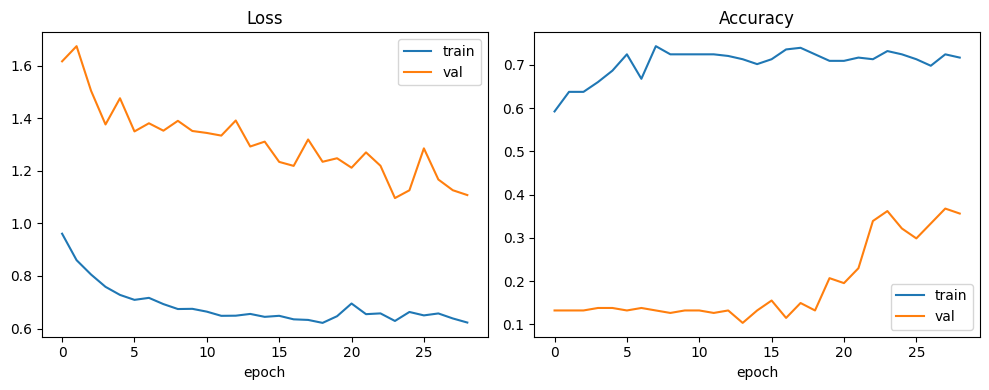

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, key, title in [(ax[0], 'loss', 'Loss'), (ax[1], 'accuracy', 'Accuracy')]:
    a.plot(history.history[key], label='train')
    a.plot(history.history['val_' + key], label='val')
    a.set_title(title); a.set_xlabel('epoch'); a.legend()
plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150)       # saved for the README
plt.show()

*Fig. 1. CNN loss and accuracy per epoch (the plot above is generated by the code, so no pasted image is needed).*

**What the curves show.**
- Training loss falls from about 0.95 to 0.62 and training accuracy levels off near 0.72, so the model is learning something.
- Validation accuracy sits at about **0.13 for the first ~17 epochs**. That is almost exactly the share of `exploration` photos in the validation set (23 of 174 = 13%). In other words, the model was predicting `exploration` for nearly everything, which is correct for 13% of this validation set because it is 86% `work_study`.
- It only rises to about 0.35 near the end. This is **not classic overfitting**; it is a train/validation mismatch. Training has 32 work/study photos and validation has 150, so the validation score mostly measures how well the model finds the class it saw least.
- Early stopping and `restore_best_weights` were chosen using this validation set, so model selection itself was shaped by that mismatch.

### Test results for the CNN

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 289ms/step
Test accuracy: 0.8
              precision    recall  f1-score   support

 exploration       0.80      0.97      0.88        38
      social       0.75      0.50      0.60         6
  work_study       0.00      0.00      0.00         6

    accuracy                           0.80        50
   macro avg       0.52      0.49      0.49        50
weighted avg       0.70      0.80      0.74        50



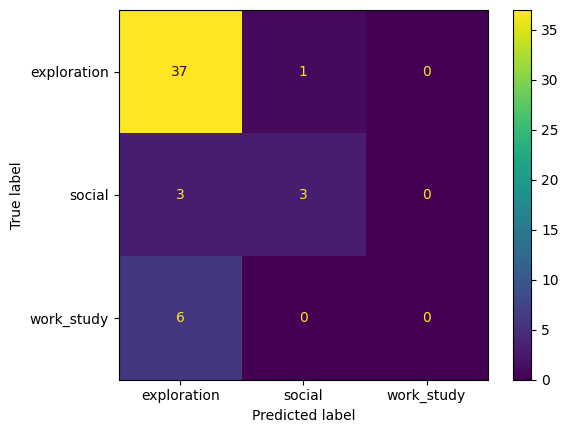

In [11]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

probs = tf.nn.softmax(model.predict(test_ds), axis=1).numpy()
pred = probs.argmax(axis=1)

print('Test accuracy:', round(accuracy_score(y_test, pred), 3))
# zero_division=0 sets precision to 0 for a class that is never predicted (and hides the warning)
print(classification_report(y_test, pred, target_names=CLASSES, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASSES).plot()
plt.savefig('cnn_confusion_matrix.png', dpi=150)
plt.show()

*Table 1. Per-class results for the small CNN on the test set (n = 50).*

| class | precision | recall | F1 | photos |
|---|---|---|---|---|
| exploration | 0.80 | 0.97 | 0.88 | 38 |
| social | 0.75 | 0.50 | 0.60 | 6 |
| work_study | 0.00 | 0.00 | 0.00 | 6 |

*Fig. 2. Confusion matrix (rows = true class, columns = predicted).*

**Reading the confusion matrix.**
- `exploration`: 37 of 38 correct, 1 mistaken for `social`.
- `social`: 3 of 6 correct, the other 3 predicted as `exploration`. Half of my social photos look like scenery to the model, which supports my worry that these two classes overlap.
- `work_study`: **0 of 6 correct**, all predicted as `exploration`. This is the main failure.

**Why work_study precision is 0.** The model never predicted `work_study` at all, so the precision formula is 0/0 (undefined). scikit-learn reports 0 (and warns when `zero_division` isn't set). I got the zero division warning on the previous runs and for the final version, I decided to address it(See the comment in the code cell above).This also pulls macro-F1 down to 0.494: it averages the three class F1 scores (0.88, 0.60, 0.00) equally, so one missed class costs a lot even though accuracy is 80%.

**Likely reasons:** (1) class imbalance, since `exploration` is 76% of test; (2) only 32 work/study photos in train and a tiny model with 23,779 parameters; (3) work photos may share backgrounds with other classes; (4) only 6 photos per minority class in test, so each error moves the metrics a lot; (5) overlapping `social`/`exploration` labels.

## 8. Metrics used
**Accuracy** = correct predictions / total predictions. It can be misleading with imbalanced classes: the baseline gets 76% by always guessing `exploration`.

**F1 per class** combines precision (of photos predicted as this class, how many really are?) and recall (of photos that really are this class, how many did we find?):

$$F1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

**Macro-F1** averages the three class F1 scores equally, so a rare class counts as much as a common one:

$$\text{Macro-F1} = \frac{F1_{\text{exploration}} + F1_{\text{social}} + F1_{\text{work\_study}}}{3}$$

## 9. Conditions 2 and 3: logistic regression on image features
Same idea as in class (logistic regression), but instead of feeding pixels I feed a compact description of each photo:

- **Condition 2, color features (30 numbers):** an 8-bin histogram per color channel (24) plus each channel's mean and standard deviation (6). This only sees *color*, not objects.
- **Condition 3, MobileNetV2 embedding (1,280 numbers):** MobileNetV2 is a CNN pretrained on ImageNet. I **freeze** it (no training) and use its output as features; only the logistic regression on top is trained.

Both use `StandardScaler`, `C=0.1` (stronger regularization, since there are few photos) and `class_weight='balanced'` (rare classes count more).

In [12]:
#Load all cached images into one array, keeping the train/val/test masks ---
from sklearn.metrics import f1_score

all_paths = train_paths + val_paths + test_paths
y_all = np.concatenate([y_train, y_val, y_test])
groups_all = np.concatenate([train['session'].values, val['session'].values, test['session'].values])
dates_all = pd.concat([train['date'], val['date'], test['date']]).dt.date.values

idx = np.arange(len(all_paths))
is_train = idx < len(train_paths)
is_val   = (idx >= len(train_paths)) & (idx < len(train_paths) + len(val_paths))
is_test  = idx >= len(train_paths) + len(val_paths)

X_img = np.stack([np.array(Image.open(p).convert('RGB')) for p in all_paths])   # uint8
print(X_img.shape)

(489, 224, 224, 3)


In [13]:
# Feature set 1: color histograms + channel mean/std
def color_feats(img, bins=8):
    f = [np.histogram(img[..., c], bins=bins, range=(0, 255), density=True)[0] for c in range(3)]
    f += [img.mean(axis=(0, 1)) / 255, img.std(axis=(0, 1)) / 255]
    return np.concatenate(f)
X_color = np.stack([color_feats(im) for im in X_img])

# Feature set 2: frozen MobileNetV2 embeddings
base = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False,
                                         weights='imagenet', pooling='avg')   # frozen feature extractor
X_emb = base.predict(tf.keras.applications.mobilenet_v2.preprocess_input(X_img.astype('float32')),
                     batch_size=32, verbose=0)
print(X_color.shape, X_emb.shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(489, 30) (489, 1280)


In [14]:
#Fit each model on train, score on test
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def lr():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced'))

def fit_eval(model, X):
    p = model.fit(X[is_train], y_all[is_train]).predict(X[is_test])
    return accuracy_score(y_all[is_test], p), f1_score(y_all[is_test], p, average='macro')

rows = [
    ('Majority baseline',                          *fit_eval(DummyClassifier(strategy='most_frequent'), X_color)),
    ('Color histograms + logistic regression',     *fit_eval(lr(), X_color)),
    ('MobileNetV2 features + logistic regression', *fit_eval(lr(), X_emb)),
    ('Small CNN',                                  accuracy_score(y_test, pred), f1_score(y_test, pred, average='macro')),
]
results = pd.DataFrame(rows, columns=['model', 'test accuracy', 'test macro-F1'])
print(results.round(3).to_string(index=False))

                                     model  test accuracy  test macro-F1
                         Majority baseline           0.76          0.288
    Color histograms + logistic regression           0.64          0.527
MobileNetV2 features + logistic regression           1.00          1.000
                                 Small CNN           0.80          0.494


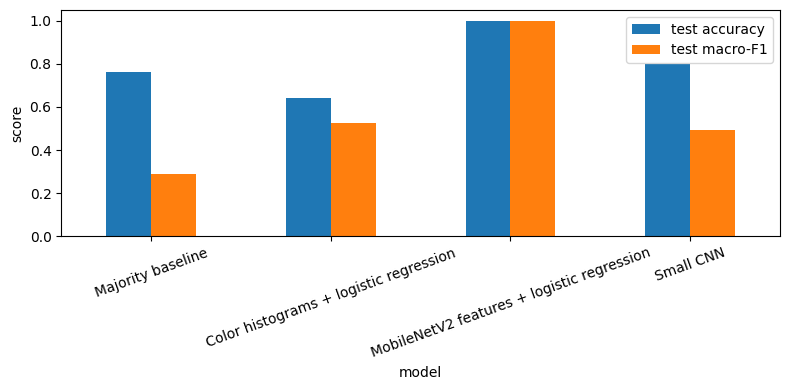

In [15]:
results.set_index('model')[['test accuracy', 'test macro-F1']].plot.bar(figsize=(8, 4), rot=20)
plt.ylim(0, 1.05); plt.ylabel('score'); plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight'); plt.show()

*Table 2. Test results (n = 50).*

| model | test accuracy | test macro-F1 |
|---|---|---|
| Majority baseline | 0.76 | 0.288 |
| Color histograms + logistic regression | 0.64 | 0.527 |
| MobileNetV2 features + logistic regression | 1.00 | 1.000 |
| Small CNN | 0.80 | 0.494 |

**Reading the table.**
- **Baseline:** 76% accuracy but macro-F1 of only 0.288. It shows why accuracy alone misleads here.
- **Color + logistic regression:** *lower* accuracy than the baseline but *higher* macro-F1. It gets some minority-class photos right instead of always guessing `exploration`, so it is the more useful model of the two.
- **MobileNetV2 + logistic regression:** perfect on test. Pretrained features already encode objects (laptops, people, landscapes), which is exactly what separates my classes. But a perfect score on 50 photos deserves suspicion; see below.
- **Small CNN:** beats the baseline by only 2 photos (40 vs 38 correct), which is within noise, and it misses `work_study` entirely.

### 9b. Is the 1.00 real? Leakage checks
A perfect score can mean the test set is easy or that test photos are near-copies of training photos. Two checks (run these and paste the numbers into the discussion):

1. **Nearest-neighbour similarity:** for each test photo, how similar is its closest training photo (cosine similarity of embeddings)? Values near 1.0 mean near-duplicates.
2. **Day overlap:** how many test photos were taken on a day that also appears in train, per class?
3. **Grouped 5-fold CV:** repeat the evaluation on 5 different session-grouped splits. A model that is really good should do well on all of them, not just one 50-photo test set.

In [16]:
# 1) nearest-neighbour similarity between each test photo and the train set
from sklearn.preprocessing import normalize
E = normalize(X_emb)
nearest = (E[is_test] @ E[is_train].T).max(axis=1)
print(f'Nearest-train cosine similarity of test photos: median {np.median(nearest):.2f}, '
      f'min {nearest.min():.2f}, max {nearest.max():.2f}')
print(f'Test photos with similarity > 0.90: {(nearest > 0.90).sum()} of {is_test.sum()}')

# 2) day overlap: test photos taken on a day that also appears in train
train_days = set(dates_all[is_train])
test_df = pd.DataFrame({'label': np.array(CLASSES)[y_all[is_test]],
                        'same_day_in_train': [d in train_days for d in dates_all[is_test]]})
print(test_df.groupby('label')['same_day_in_train'].agg(['sum', 'count']))

Nearest-train cosine similarity of test photos: median 0.66, min 0.52, max 0.78
Test photos with similarity > 0.90: 0 of 50
             sum  count
label                  
exploration   17     38
social         3      6
work_study     3      6


In [17]:
# 3) grouped 5-fold CV (whole sessions stay together; every photo is tested once)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

def cv_scores(X):
    accs, f1s = [], []
    for tr, te in cv.split(X, y_all, groups_all):
        p = lr().fit(X[tr], y_all[tr]).predict(X[te])
        accs.append(accuracy_score(y_all[te], p))
        f1s.append(f1_score(y_all[te], p, average='macro'))
    return np.mean(accs), np.std(accs), np.mean(f1s), np.std(f1s)

for name, X in [('Color + LR', X_color), ('MobileNetV2 + LR', X_emb)]:
    a, sa, f, sf = cv_scores(X)
    print(f'{name}: accuracy {a:.2f} +/- {sa:.2f}, macro-F1 {f:.2f} +/- {sf:.2f}')

Color + LR: accuracy 0.68 +/- 0.06, macro-F1 0.56 +/- 0.06
MobileNetV2 + LR: accuracy 0.93 +/- 0.05, macro-F1 0.89 +/- 0.09


## 10. Discussion

**How well did it work?** The best system was logistic regression on frozen MobileNetV2 features (1.00 accuracy, 1.00 macro-F1 on test). The CNN I trained from scratch reached 0.80 accuracy but never predicted `work_study`, and its macro-F1 (0.494) is barely above the color-feature model (0.527). The baseline shows why I need more than accuracy: 0.76 accuracy, 0.288 macro-F1.

**Why I don't fully trust the 1.00.** The test set is only 50 photos with 6 per minority class, so one photo is worth 2 points; for the CNN's 0.80 the 95% interval is roughly ±0.11. I also took about 60 work/study photos on a single day to balance classes, and even with 15-minute sessions, photos from the same day can end up in both train and test. I also can't rule out that pretrained features simply separate laptop screens from scenery easily, and that my labels for `social` vs `exploration` are fuzzy because I couldn't fully separate them myself, which is an issue with my raw data and the logic of seperation between the classes.

**Why the CNN failed on work_study, and what I'd change.** It is a 23,779-parameter network trained from scratch on a few hundred photos, with 32 work/study training photos, imbalanced classes, and a validation set (86% work/study) that looked very different from training. Next time I would (1) split by whole *days* so same-day photos can't straddle splits, (2) collect work/study photos in varied places and on different days instead of many on one day, (3) use class weights, and (4) fine-tune a pretrained network instead of training from scratch.(this was done to adhere the requirements of this assignment).

## 11. Code
Repository: [link text](https://github.com/SyuzannaKhalatyaning/CS156-Assignment). This notebook contains all outputs; run top to bottom on Colab with the `data` folder on Drive.

## 12. References
- Murphy, K. P. (2022). *Probabilistic machine learning: An introduction.* MIT Press.
- Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. *CVPR*, 4510-4520.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *JMLR, 12*, 2825-2830.
- TensorFlow. Image classification. https://www.tensorflow.org/tutorials/images/classification
- TensorFlow. Transfer learning and fine-tuning. https://www.tensorflow.org/tutorials/images/transfer_learning
- Aniskheloufi. (2021). Preprocess image data for machine learning. *Analytics Vidhya.* https://medium.com/analytics-vidhya/preprocess-image-data-for-machine-learning-37df531583d8
- Roboflow. (2025). What is image preprocessing and augmentation? https://roboflow.com/blog/why-preprocess-augment
- de Jin, R. Image classification, computer vision from scratch (pt. 1). https://medium.com/@ricodedeijn/image-classification-computer-vision-from-scratch-pt-1-d02033edd70d